# Spontaneous time-reversal symmetry breaking by optical-phonon lasing

Run the setup cell once. Each figure then has two independent steps. **Calculate and save** runs the model and writes its arrays to `data/`. **Load and plot** reads only that figure’s archive, exports a vector PDF and 300 dpi PNG in the working directory, and displays the result. The package includes all five archives. To edit a figure, skip its calculation cell and change its plotting cell directly. 

All model energies are in eV unless a name or label specifies another unit. The standalone script offers the same calculations and plots. The common font size multiplier is `FONT_SCALE` in the setup cell. Dependencies are Python 3, NumPy, SciPy, Matplotlib, and a Jupyter Python kernel.

In [6]:
from __future__ import annotations
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import spence

import scienceplots

plt.style.use(['science', 'no-latex'])


# ------------------------------------------------------------------ constants
HBAR = 1.054571817e-34; QE = 1.602176634e-19; AMU = 1.66053906660e-27
KB = 8.617333262e-5                 # eV/K
CM = 1.239841984e-4                 # eV per cm^-1
T_HOP = 2.8                         # eV
A_LAT = 2.46                        # Angstrom
HW0 = 0.196                         # eV, E2g phonon
D2 = 45.6                           # (eV/A)^2, <D^2_Gamma>_F  (DFT)
DTDD = np.sqrt(4.0 * D2 / 9.0)      # eV/A, bond-stretching derivative
M_C = 12.011 * AMU
ER = HW0 / 2.0                      # resonant electron energy
HV = np.sqrt(3.0) * T_HOP * A_LAT / 2.0          # hbar v_F in eV*Angstrom
A_UC_CM2 = np.sqrt(3.0) * (A_LAT * 1e-8) ** 2 / 2.0
GS = 2

# local coupling scale  gbar^2 = (9/2) (dt/dd)^2 hbar^2 / (M_C hbar w0)
GBAR = np.sqrt(4.5 * (DTDD * QE / 1e-10) ** 2 * HBAR ** 2
               / (M_C * HW0 * QE)) / QE
# Landau-damping FWHM at T = 0 and charge neutrality
GAMMA_E = GS * GBAR ** 2 * HW0 / (4.0 * np.sqrt(3.0) * T_HOP ** 2)

SQ3 = np.sqrt(3.0)
DELTAS = np.array([[0.0, 1/SQ3], [-0.5, -0.5/SQ3], [0.5, -0.5/SQ3]])
THETAS = np.array([np.pi/2, np.pi/2 + 2*np.pi/3, np.pi/2 + 4*np.pi/3])
B1 = 2*np.pi*np.array([1.0, -1/SQ3]); B2 = 2*np.pi*np.array([0.0, 2/SQ3])
K_PT = (2*B1 + B2)/3.0; KP_PT = (B1 + 2*B2)/3.0


# ------------------------------------------------------------- gain medium
class Medium:
    """Inverted Dirac plasma coupled to the two circular E2g components."""

    def __init__(self, mu, Te, gperp=0.020, Gr=0.020, gan_cm=1.5,
                 nE=900, nphi=48, Ecut=1.0):
        self.mu, self.Te, self.gperp, self.Gr = mu, Te, gperp, Gr
        self.kappa = 0.5 * gan_cm * CM
        self.E = (np.arange(nE) + 0.5) * Ecut / nE
        self.dE = Ecut / nE
        self.phi = (np.arange(nphi) + 0.5) * 2*np.pi / nphi
        self.W0 = np.tanh((mu - self.E) / (2 * KB * Te))
        self.L = gperp / ((2*self.E - HW0) ** 2 + gperp ** 2)
        # weight so that  sum(w * W0 * L)  ->  W0(E_r) in the narrow limit
        self.w = (2.0 / (np.pi * ER)) * self.E * self.dE
        self.e2 = np.exp(2j * self.phi)

    def J(self):
        """Normalised inversion integral; electronic FWHM = -GAMMA_E * J."""
        return float(np.sum(self.w * self.W0 * self.L))

    def G0(self):
        return 0.5 * GAMMA_E * self.J()

    def rhs(self, AR, AL):
        """Time derivative (energy units) of the complex amplitudes."""
        d = AR - AL * self.e2[None, :]                       # (1, nphi)
        S = self.L[:, None] * np.abs(d) ** 2 / self.Gr        # saturation
        core = (self.w * self.W0 * self.L)[:, None] / (1.0 + S)
        fR = np.sum(core * d) / len(self.phi)
        fL = np.sum(core * (AL - AR * np.conj(self.e2)[None, :])) / len(self.phi)
        return (-self.kappa * AR + 0.5 * GAMMA_E * fR,
                -self.kappa * AL + 0.5 * GAMMA_E * fL)

    def gain_circular(self, A):
        return 0.5 * GAMMA_E * float(np.sum(
            self.w * self.W0 * self.L / (1.0 + A * A * self.L / self.Gr)))

    def steady_circular(self):
        if self.G0() <= self.kappa:
            return 0.0
        hi = 1e-3
        while self.gain_circular(hi) > self.kappa and hi < 5.0:
            hi *= 1.5
        return brentq(lambda a: self.gain_circular(a) - self.kappa, 1e-9, hi)

    def cubic_B(self):
        return 0.5 * GAMMA_E * float(np.sum(
            self.w * self.W0 * self.L ** 2)) / self.Gr


def carrier_density_cm2(mu, Te):
    """Electron density of one band (both spins and valleys), cm^-2."""
    x = mu / (KB * Te)
    # -Li2(-e^x) via scipy.special.spence:  Li2(z) = spence(1 - z)
    F1 = -spence(1.0 + np.exp(np.minimum(x, 500.0)))
    return (2.0 / np.pi) * (KB * Te / HV) ** 2 * F1 * 1e16


# ------------------------------------------------------- exact Floquet tools
def floquet_states(ks, lamR, omega, nsteps, t0=1.0, lamL=0.0):
    ks = np.atleast_2d(ks); N = len(ks)
    dt = (2*np.pi/omega)/nsteps
    ph = np.exp(1j*(ks @ DELTAS.T))
    U = np.zeros((N, 2, 2), complex); U[:, 0, 0] = U[:, 1, 1] = 1.0
    for n in range(nsteps):
        wt = 2*np.pi*(n + 0.5)/nsteps
        hop = t0*(1 + lamR*np.cos(wt - THETAS) + lamL*np.cos(wt + THETAS))
        f = ph[:, 0]*hop[0] + ph[:, 1]*hop[1] + ph[:, 2]*hop[2]
        bx, by = -f.real, f.imag
        nb = np.sqrt(bx*bx + by*by); nbs = np.where(nb > 1e-30, nb, 1.0)
        c = np.cos(nb*dt); s = np.sin(nb*dt)/nbs
        st = np.empty((N, 2, 2), complex)
        st[:, 0, 0] = c; st[:, 1, 1] = c
        st[:, 0, 1] = -1j*s*(bx - 1j*by); st[:, 1, 0] = -1j*s*(bx + 1j*by)
        U = st @ U
    ev, V = np.linalg.eig(U)
    eps = -np.angle(ev)*omega/(2*np.pi)
    o = np.argsort(eps, axis=1)
    return np.take_along_axis(eps, o, 1), np.take_along_axis(V, o[:, None, :], 2)


def chern_map(lamR, lamL, omega, nk, nsteps):
    f = np.arange(nk)/nk
    K = (f[:, None, None]*B1 + f[None, :, None]*B2).reshape(-1, 2)
    eps, V = floquet_states(K, lamR, omega, nsteps, lamL=lamL)
    gap = eps[:, 1] - eps[:, 0]
    U = V[:, :, 0].reshape(nk, nk, 2)
    # H(k+G)=D_G H(k) D_G^dagger in the embedded-site Bloch basis.
    # Sew only the links that cross a reciprocal boundary. This preserves
    # the local Berry curvature in the original orbital embedding.
    def link(axis, reciprocal):
        neighbor = np.roll(U, -1, axis=axis)
        boundary = [-1, slice(None)] if axis == 0 else [slice(None), -1]
        neighbor[tuple(boundary) + (0,)] *= np.exp(1j * reciprocal @ DELTAS[0])
        overlap = np.sum(U.conj() * neighbor, axis=-1)
        if np.any(np.abs(overlap) < 1e-14):
            raise ValueError("Undefined Berry link: refine the mesh.")
        return overlap / np.abs(overlap)
    link1 = link(0, B1)
    link2 = link(1, B2)
    F = -np.angle(link1 * np.roll(link2, -1, axis=0)
                  * np.roll(link1, -1, axis=1).conj() * link2.conj())
    return F.sum()/(2*np.pi), F, gap.min(), (omega - gap).min()



# Figure fonts are specified in points. Every size uses the same scale.
FONT_SCALE = 1.2
NAMES = ('fig1_negative_landau_damping', 'fig2_polarization_selection',
         'fig3_symmetry_breaking', 'fig4_floquet_mass', 'fig5_topology')


def font(points):
    return FONT_SCALE * points


def style():
    plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm",
                         "font.size": font(9), "axes.labelsize": font(9),
                         "xtick.labelsize": font(9), "ytick.labelsize": font(9),
                         "legend.fontsize": font(7), "legend.frameon": False,
                         "axes.linewidth": 0.8, "figure.dpi": 130,
                         "pdf.fonttype": 42})


def save_data(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, **arrays)


def load_data(path):
    with np.load(path, allow_pickle=False) as data:
        return dict(data)


def record(out, key, values):
    path = Path(out) / "summary.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    summary = json.loads(path.read_text()) if path.exists() else {}
    summary[key] = values
    path.write_text(json.dumps(summary, indent=2) + "\n")


def finish(fig, axes, out, name):
    # Use the outer edge of each y label and the top spine of the row.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    row_top = max(ax.get_window_extent(renderer).y1 for ax in axes)
    for letter, ax in zip("abc", axes):
        box = (ax.yaxis.label.get_window_extent(renderer) if ax.get_ylabel()
               else ax.get_tightbbox(renderer))
        x, y = fig.transFigure.inverted().transform((box.x0, row_top))
        fig.text(x, y, f"({letter})", ha="left", va="center", fontsize=font(9))
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / (name + ".pdf"))
    fig.savefig(out / (name + ".png"), dpi=300)
    plt.close(fig)


def three_panels():
    fig, ax = plt.subplots(1, 3, figsize=(9.53, 3.55))
    fig.subplots_adjust(left=.077, right=.97, bottom=.20, top=.87, wspace=.47)
    return fig, ax

def shift_ax(ax, dx=0.0, dy=0.0, scale=1.0):
    pos = ax.get_position()
    new_w = pos.width * scale
    new_h = pos.height * scale
    new_x0 = pos.x0 + (pos.width - new_w) / 2 + dx
    new_y0 = pos.y0 + (pos.height - new_h) / 2 + dy
    ax.set_position([new_x0, new_y0, new_w, new_h])

def set_panel_label(fig, ax, label_str, x=-0.15, y=1.05, fontsize=12):
    for t in list(ax.texts):
        if t.get_text().strip() == label_str:
            t.remove()
    for t in list(fig.texts):
        if t.get_text().strip() == label_str:
            t.remove()
            
    ax.text(x, y, label_str, transform=ax.transAxes,
            fontsize=fontsize, va="top", ha="left")

from IPython.display import Image, display

ROOT = Path.cwd()
DATA = ROOT / "data"
style()

## Figure 1. Electronic linewidth and gain threshold

Stores linewidths, the finite-dephasing gain map, carrier-density contours, and narrow-line threshold curves. Energy axes in the archive are in meV.

The first cell writes the archive. The following cell controls the figure formatting.

In [7]:
# Calculate and save Figure 1
def calculate1(path):
    mus = np.linspace(0, .45, 181)
    temperatures = np.array([300, 1000, 2000])
    linewidth = [[-GAMMA_E * Medium(mu, T).J()/CM for mu in mus] for T in temperatures]
    medium = Medium(0, 300)
    def equilibrium(mu):
        def f(e):
            return 1/(1 + np.exp(np.clip((e-mu)/(KB*300), -60, 60)))
        return -GAMMA_E * np.sum(medium.w * medium.L * (f(medium.E)-f(-medium.E)))/CM
    
    grid_mu = np.linspace(0, .45, 91)
    grid_T = np.linspace(100, 3000, 59)
    gain = [[GAMMA_E*Medium(mu, T, nE=500).J()/CM for mu in grid_mu] for T in grid_T]
    X, Y = np.meshgrid(grid_mu, grid_T)
    losses = np.array([1.5,4.])
    narrow = ER + 2*KB*grid_T[:,None]*np.arctanh(losses*CM/GAMMA_E)
    save_data(path, mu=mus*1000, temperatures=temperatures, linewidth=linewidth,
              equilibrium=[equilibrium(mu) for mu in mus], grid_mu=grid_mu*1000,
              grid_T=grid_T, gain=gain, density=carrier_density_cm2(X,Y)/1e12,
              losses=losses, narrow_mu=narrow*1000, resonance=ER*1000)
    result = {"gamma_e_cm": GAMMA_E/CM, "gamma_e_meV": GAMMA_E*1000,
              "gbar_eV": GBAR, "dtdd_eV_A": DTDD, "J_mu250_T1000": Medium(.25,1000).J()}
    for loss in losses:
        for T in (300,1000):
            th = brentq(lambda mu: GAMMA_E*Medium(mu,T).J()-loss*CM, 0,.5)
            approx = ER + 2*KB*T*np.arctanh(loss*CM/GAMMA_E)
            suffix = f"T{T}_gan{loss:g}"
            result["mu_th_meV_"+suffix] = th*1000
            result["mu_th_narrow_meV_"+suffix] = approx*1000
            result["n_th_"+suffix+"_1e12"] = carrier_density_cm2(th,T)/1e12
        result[f"W_th_gan{loss:g}"] = loss*CM/GAMMA_E
    return result

metrics_1 = calculate1(DATA / (NAMES[0] + ".npz"))
record(ROOT, "fig1", metrics_1)
print("Wrote", DATA / (NAMES[0] + ".npz"))

Wrote /home/mainadmin/solihin/symm-break-circ-phonon/data/fig1_negative_landau_damping.npz


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


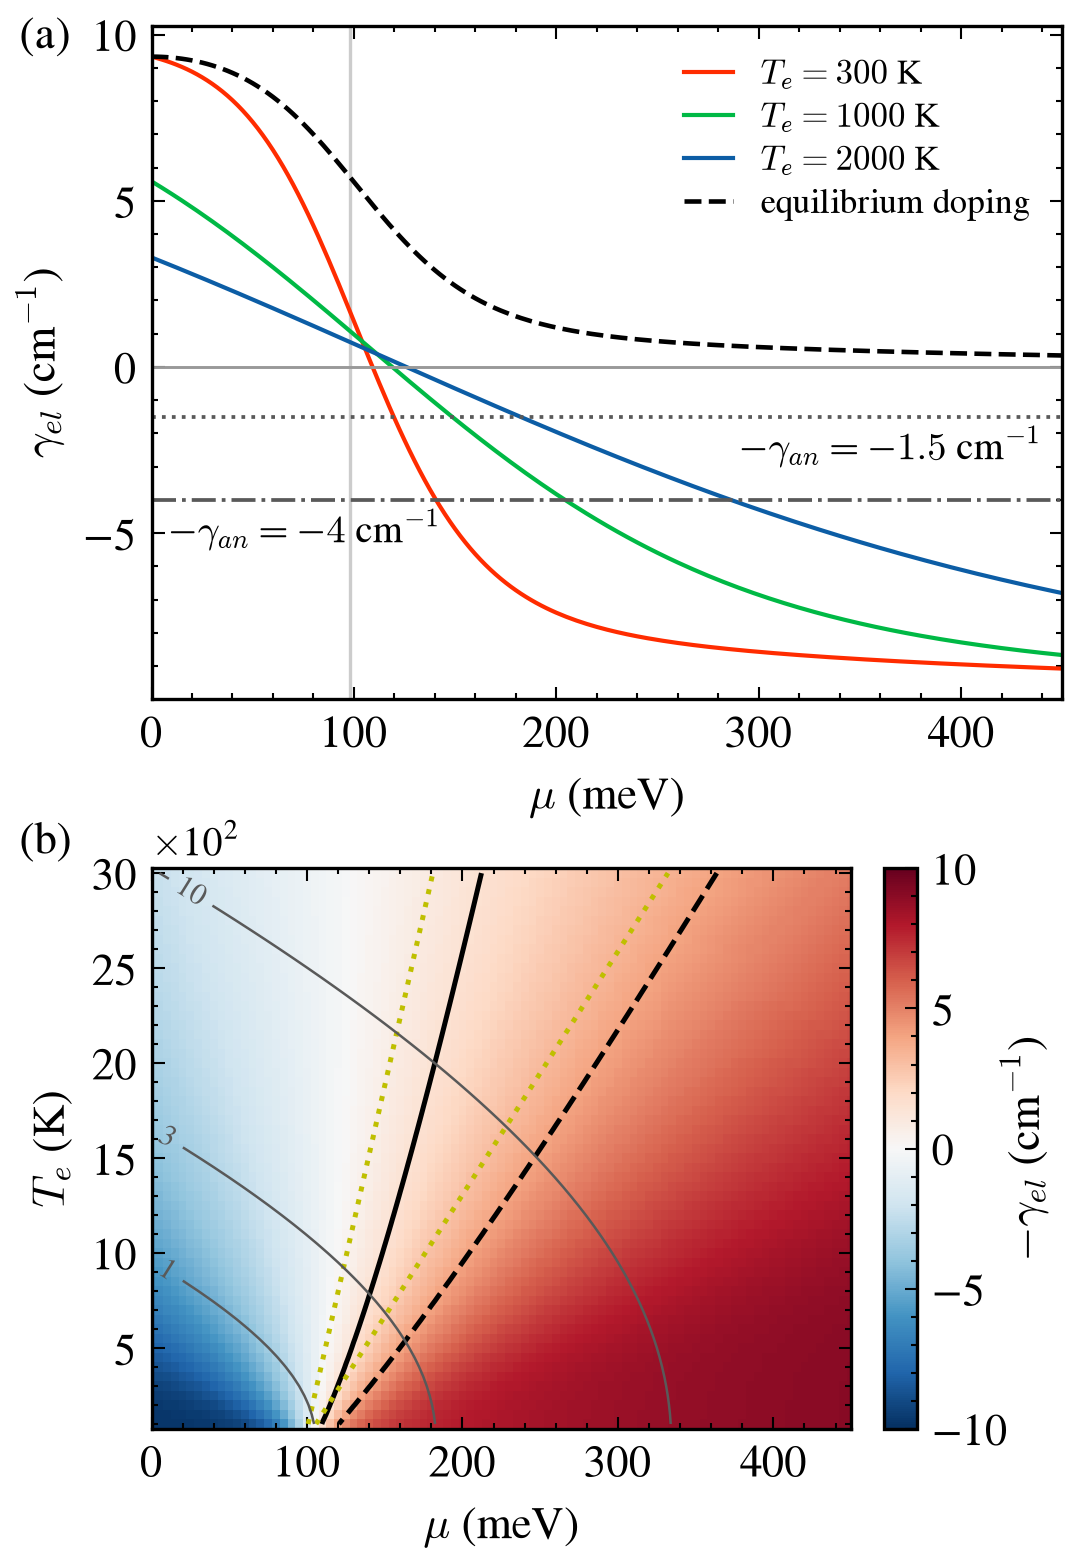

In [8]:
from matplotlib.ticker import ScalarFormatter

def plot1(path, out):
    d = load_data(path)
    
    fig = plt.figure(figsize=(4.4, 5.874))
    
    a  = fig.add_axes([0.18, 0.534, 0.69, 0.382])
    b  = fig.add_axes([0.18, 0.120, 0.53, 0.318])
    cb = fig.add_axes([0.735, 0.120, 0.025, 0.318])

    # --- Panel (a) ---
    for curve, T, c in zip(d["linewidth"], d["temperatures"], ["C3", "C1", "C0"]):
        a.plot(d["mu"], curve, c=c, label=rf"$T_e={T}$ K")
    a.plot(d["mu"], d["equilibrium"], "k--", lw=1.1, label="equilibrium doping")
    a.axhline(0, color=".6", lw=.7)
    for loss, ls, x_pos in zip(d["losses"], [":", "-."], [290, 8]):
        a.axhline(-loss, color=".35", ls=ls, lw=.9)
        a.text(x_pos, -loss - .25, rf"$-\gamma_{{an}}={-loss:g}$ cm$^{{-1}}$",
               fontsize=font(7.75), color="k", va="top")
    a.axvline(d["resonance"], color=".8", lw=.8, zorder=0)
    a.set(xlim=(0, 450), xlabel=r"$\mu$ (meV)", ylabel=r"$\gamma_{el}$ (cm$^{-1}$)",
          xticks=[0, 100, 200, 300, 400])
    a.legend(loc="upper right", handlelength=1.4, labelspacing=.23)

    # --- Panel (b) ---
    pc = b.pcolormesh(d["grid_mu"], d["grid_T"], d["gain"], cmap="RdBu_r",
                      vmin=-10, vmax=10, shading="auto", rasterized=True)
    for i, ls in enumerate(["-", "--"]):
        b.contour(d["grid_mu"], d["grid_T"], d["gain"], levels=[d["losses"][i]],
                  colors="k", linewidths=1.2, linestyles=ls)
        b.plot(d["narrow_mu"][:, i], d["grid_T"], "y:", lw=1.2)
    cs = b.contour(d["grid_mu"], d["grid_T"], d["density"], levels=[1, 3, 10], colors=".35", linewidths=.6)
    b.clabel(cs, fmt="%g", fontsize=font(6))
    
    b.set(xlim=(0, 450), xlabel=r"$\mu$ (meV)", ylabel=r"$T_e$ (K)",
          xticks=[0, 100, 200, 300, 400], yticks=[500, 1000, 1500, 2000, 2500, 3000])

    fmt_y = ScalarFormatter(useMathText=True)
    fmt_y.set_powerlimits((2, 2))
    b.yaxis.set_major_formatter(fmt_y)
    b.yaxis.get_offset_text().set_fontsize(font(8))

    cbar = fig.colorbar(pc, cax=cb, ticks=[-10, -5, 0, 5, 10])
    cbar.set_label(r"$-\gamma_{el}$ (cm$^{-1}$)", labelpad=-2)

    pos_a = (0.08, 0.897)
    pos_b = (0.08, 0.440)

    fig.text(*pos_a, "(a)", ha="left", va="bottom", fontsize=font(9))
    fig.text(*pos_b, "(b)", ha="left", va="bottom", fontsize=font(9))

    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / (NAMES[0] + ".pdf"))
    fig.savefig(out / (NAMES[0] + ".png"), dpi=300)
    plt.close(fig)

plot1(DATA / (NAMES[0] + ".npz"), ROOT / "plots")
display(Image(filename=str(ROOT / "plots" / (NAMES[0] + ".png")), width=480))

## Figure 2. Polarization selection

Stores normalized angular patterns, net gain, the two components of the flow, and the linear saddle. Net gain is an amplitude growth energy in meV.

The first cell writes the archive. The following cell controls the figure formatting.

In [9]:
# Calculate and save Figure 2
def calculate2(path):
    m = Medium(.25, 1000)
    Ac = m.steady_circular()
    Al = brentq(lambda a: m.rhs(a,a)[0].real, 1e-6, 2*Ac)
    g = m.G0()-m.kappa
    def saturation_ratio(a):
        eps = 1e-9
        self_loss = g-m.rhs(a,0)[0].real/a
        cross_loss = g-m.rhs(a,eps)[1].real/eps
        return cross_loss/self_loss
    intensities = np.linspace(1e-8, (1.6*Ac)**2, 80)
    def net(I, chi):
        ar, al = np.sqrt(I*(1+np.array([chi,-chi]))/2)
        r, l = m.rhs(ar, al)
        return (ar*r.real+al*l.real)/I
    chi = [1., .6, 0.]
    gains = [[net(I,h)*1000 for I in intensities] for h in chi]
    grid = np.linspace(1e-4, 1.25*Ac, 23)
    U, V = np.zeros((2,len(grid),len(grid)))
    for i, al in enumerate(grid):
        for j, ar in enumerate(grid):
            r, l = m.rhs(ar,al)
            U[i,j], V[i,j] = r.real, l.real
    ph = np.linspace(0, 2*np.pi, 361)
    save_data(path, phi=ph, circular=np.ones_like(ph), linear=2*np.sin(ph)**2,
              intensity=intensities/Ac**2, gain=gains, chi=chi, grid=grid/Ac,
              U=U, V=V, saddle=Al/Ac)
    small = 1e-6
    r,l = m.rhs(Al*(1+small),Al*(1-small))
    return {"ratio_small": saturation_ratio(1e-4), "ratio_at_Ac": saturation_ratio(Ac),
            "A_c_meV": Ac*1000, "A_lin_each_meV": Al*1000,
            "I_lin_over_I_c": 2*Al**2/Ac**2,
            "transverse_rate_meV": m.rhs(Ac,1e-9)[1].real/1e-9*1000,
            "linear_instability_meV": (r-l).real/(2*Al*small)*1000,
            "g_meV": g*1000, "G0_meV": m.G0()*1000, "kappa_meV": m.kappa*1000,
            "B_meV^-1": m.cubic_B()/1000, "A_cubic_meV": 1000*np.sqrt(g/m.cubic_B())}

metrics_2 = calculate2(DATA / (NAMES[1] + ".npz"))
record(ROOT, "fig2", metrics_2)
print("Wrote", DATA / (NAMES[1] + ".npz"))

Wrote /home/mainadmin/solihin/symm-break-circ-phonon/data/fig2_polarization_selection.npz


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


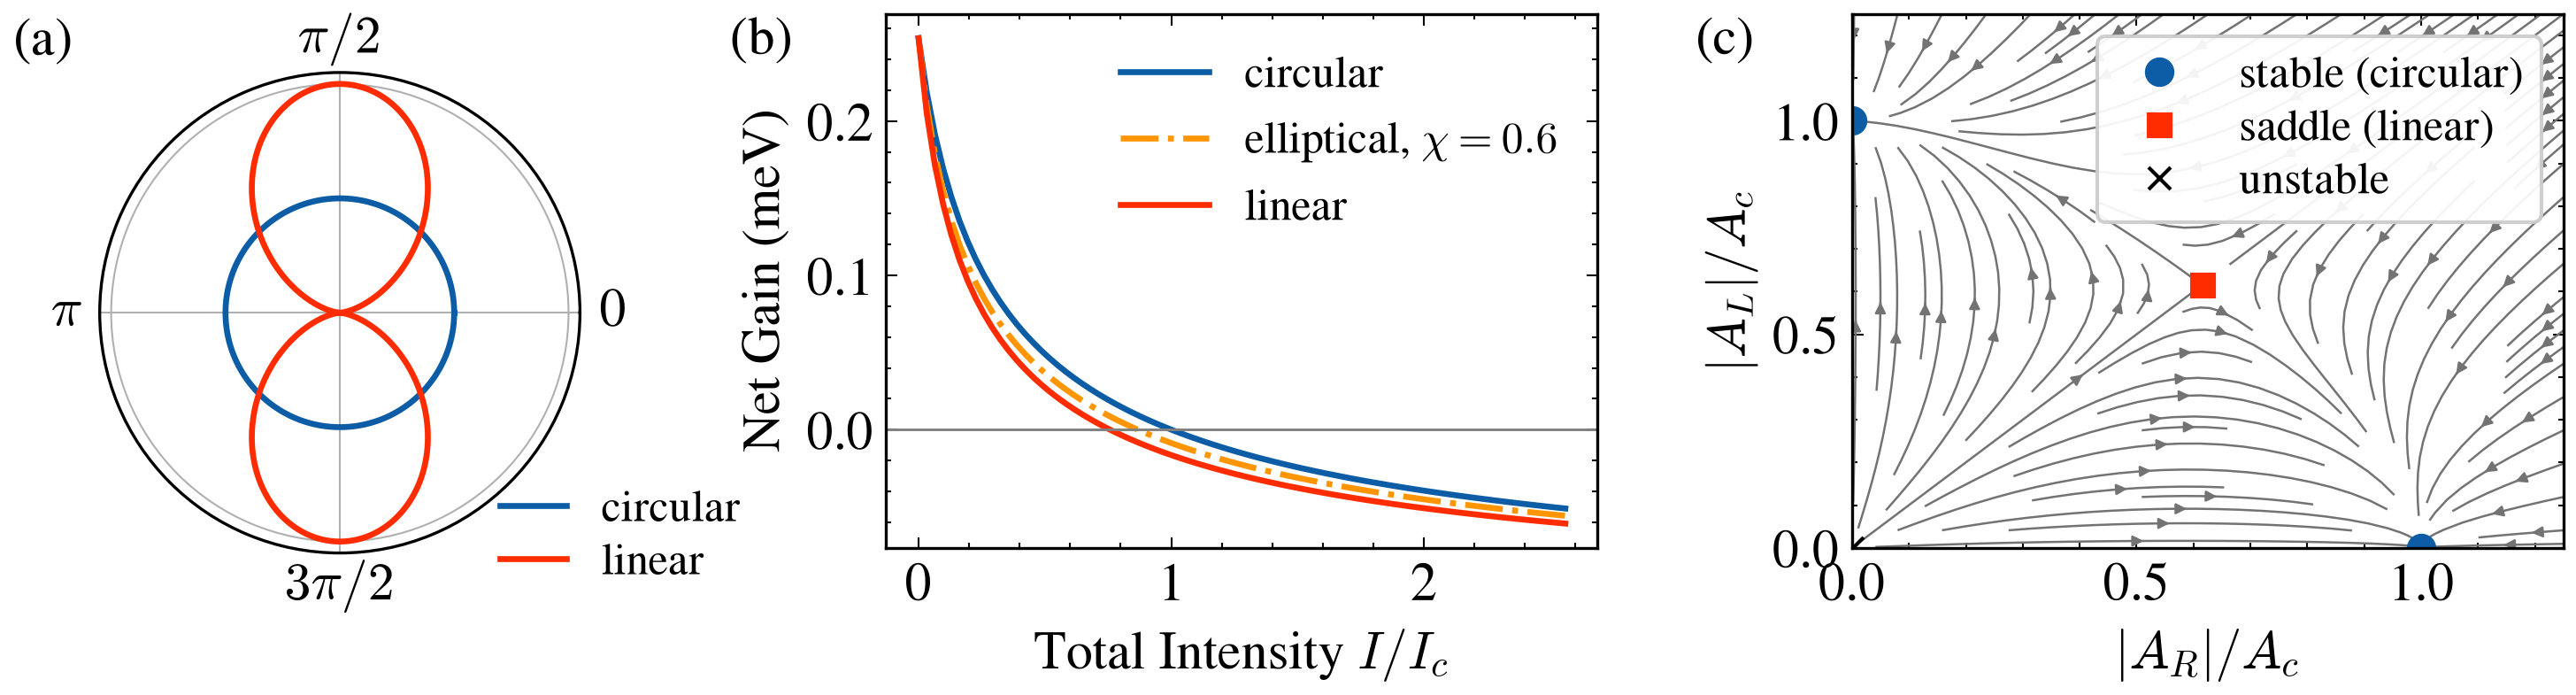

In [10]:
# Load and plot Figure 2
def plot2(path, out):
    d = load_data(path)
    fig, ax = three_panels()
    
    fig.set_size_inches(12, 3)
    
    ax[0].remove()
    a = fig.add_subplot(ax[0].get_subplotspec(), projection="polar")
    b, c = ax[1:]
    
    # --- Panel (a): Polar Plot (Otomatis persegi/bulat) ---
    a.plot(d["phi"], d["circular"], "C0", lw=1.6, label="circular")
    a.plot(d["phi"], d["linear"], "C3", lw=1.6, label="linear")
    a.set_yticks([1, 2], labels=["", ""])
    a.set_xticks(np.arange(4)*np.pi/2, labels=["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$"],
                 fontsize=font(12))
    a.tick_params(axis="x", pad=2, labelsize=font(12))
    a.legend(fontsize=font(10), loc="lower left", bbox_to_anchor=(0.75, -0.15), labelspacing=0.2, handlelength=1.5)
    
    # --- Panel (b): Line Plot (Rasio 4:3) ---
    for y, col, ls, text in zip(d["gain"], ["C0", "C2", "C3"], ["-", "-.", "-"], ["circular", r"elliptical, $\chi=0.6$", "linear"]):
        b.plot(d["intensity"], y, c=col, ls=ls, lw=1.6, label=text)
    b.axhline(0, color=".5", lw=0.7)
    b.set_xlabel(r"Total Intensity $I/I_c$", fontsize=font(12))
    b.set_ylabel("Net Gain (meV)", fontsize=font(12))
    b.tick_params(axis="both", labelsize=font(12))
    b.set_box_aspect(3 / 4)  # Rasio lebar 4 : tinggi 3
    b.legend(loc="upper right", fontsize=font(10), handlelength=2.0)
    
    # --- Panel (c): Streamplot (Rasio 4:3) ---
    c.streamplot(d["grid"], d["grid"], d["U"], d["V"], density=1.1, color=".45", linewidth=0.6, arrowsize=0.6)
    c.plot([1, 0], [0, 1], "o", color="C0", ms=7, label="stable (circular)")
    c.plot(d["saddle"], d["saddle"], "s", color="C3", ms=6, label="saddle (linear)")
    c.plot(0, 0, "kx", ms=6, label="unstable")
    c.set(xlim=(0, 1.25), ylim=(0, 1.25), xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
    c.set_xlabel(r"$|A_R|/A_c$", fontsize=font(12))
    c.set_ylabel(r"$|A_L|/A_c$", fontsize=font(12))
    c.tick_params(axis="both", labelsize=font(12))
    c.set_box_aspect(3 / 4)  # Rasio lebar 4 : tinggi 3
    c.legend(fontsize=font(10), loc="upper right", framealpha=0.93, frameon=True, labelspacing=0.2)
    
    a.set_anchor("C")
    
    finish(fig, [a, b, c], out, NAMES[1])
    
    shift_ax(a, dx=0.00, dy=-0.04, scale=0.90)
    shift_ax(b, dx=-0.05, dy=0.00)
    shift_ax(c, dx=-0.08, dy=0.00)
    
    set_panel_label(fig, a, "(a)", x=-0.18, y=1.12, fontsize=font(12))
    set_panel_label(fig, b, "(b)", x=-0.22, y=1.0, fontsize=font(12))
    set_panel_label(fig, c, "(c)", x=-0.22, y=1.0, fontsize=font(12))
    
    fig.savefig(str(Path(out) / (NAMES[1] + ".png")), dpi=300, bbox_inches="tight")
    fig.savefig(str(Path(out) / (NAMES[1] + ".pdf")), bbox_inches="tight")


plot2(DATA / (NAMES[1] + ".npz"), ROOT / "plots")
display(Image(filename=str(ROOT / "plots"/ (NAMES[1] + ".png")), width=950))

## Figure 3. Spontaneous handedness, hysteresis, and strain

Stores the eight full-model trajectories and intensities, both sweep directions, and the strain branch. The bias and strain sweeps use the cubic model. Seed 11 is reset when this cell runs.

The first cell writes the archive. The following cell controls the figure formatting.

In [11]:
# Calculate and save Figure 3
def calculate3(path, seed=11):
    rng = np.random.default_rng(seed)
    m = Medium(0.25, 1000, nE=500, nphi=32)
    Ac = m.steady_circular(); g = m.G0() - m.kappa
    n_cell = 1e-7 / A_UC_CM2                       # 10 um^2
    Dn = m.kappa * GBAR**2 / n_cell                # noise strength (eV^3)
    dt = 0.15e3                                    # in 1/eV  (0.15 hbar/meV)
    nst = 900
    traces = []
    intensities = []
    tps = (np.arange(nst)+1)*dt*6.582e-16*1e12         # ps
    finals = []
    for s in range(8):
        AR = AL = 0j; chi = np.zeros(nst)
        intensity = np.empty(nst)
        for k in range(nst):
            r = m.rhs(AR, AL)
            nz = np.sqrt(Dn*dt)*(rng.standard_normal(4) @ np.array(
                [[1, 0], [1j, 0], [0, 1], [0, 1j]]))
            AR += r[0]*dt + nz[0]; AL += r[1]*dt + nz[1]
            I = abs(AR)**2 + abs(AL)**2
            intensity[k] = I
            chi[k] = (abs(AR)**2 - abs(AL)**2)/I
        finals.append(chi[-1])
        traces.append(chi)
        intensities.append(intensity)
    # ---- cubic normal form (time in units 1/g, amplitudes in sqrt(g/B))
    def run_nf(h, delta, a0, T, dtn=0.02, noise=1e-3, record=False):
        aR, aL = a0; N = int(T/dtn); out_ = []
        for k in range(N):
            IR, IL = abs(aR)**2, abs(aL)**2
            dR = aR*((1+h) - IR - 2*IL) - 0.5j*delta*aL
            dL = aL*((1-h) - IL - 2*IR) - 0.5j*delta*aR
            z = noise*np.sqrt(dtn)*(rng.standard_normal(2)
                                    + 1j*rng.standard_normal(2))
            aR += dR*dtn + z[0]; aL += dL*dtn + z[1]
            if record: out_.append((abs(aR)**2-abs(aL)**2)/(abs(aR)**2+abs(aL)**2+1e-30))
        return (aR, aL, np.array(out_)) if record else (aR, aL)
    # statistics of handedness at zero bias
    nrun = 400; npos = 0
    for _ in range(nrun):
        aR, aL = run_nf(0.0, 0.0, (0j, 0j), 25.0, dtn=0.05)
        npos += abs(aR) > abs(aL)
    # hysteresis: sweep the bias slowly
    hs = np.concatenate([np.linspace(-0.7, 0.7, 141), np.linspace(0.7, -0.7, 141)])
    a = (1e-3+0j, 1.0+0j); loop = []
    for h in hs:
        a = run_nf(h, 0.0, a, 20.0, noise=3e-4)
        loop.append((abs(a[0])**2-abs(a[1])**2)/(abs(a[0])**2+abs(a[1])**2))
    loop = np.array(loop)
    # strain: degree of circular polarization versus linear splitting
    ds = np.linspace(0.0, 0.8, 41); chis = []
    a = (1.0+0j, 1e-3+0j)
    for d_ in ds:
        aR, aL, rec = run_nf(0.0, d_, a, 160.0, noise=1e-4, record=True)
        chis.append(np.mean(rec[len(rec)//2:])); a = (aR, aL)
    chis = np.array(chis)
    up = hs[:141][np.flatnonzero(loop[:141] > 0)[0]]
    down = hs[141:][np.flatnonzero(loop[141:] < 0)[0]]
    u = np.linspace(5/6, 1, 200)
    save_data(path, time_ps=tps, chirality=traces, intensity=intensities,
              h=hs, loop=loop, split=ds, mean_chirality=chis, seed=seed,
              analytic_split=np.sqrt(2*(3*u-2)*(1-u)), analytic_chi=np.sqrt(3-2/u))
    return {"finals": finals, "fraction_R_of_400": npos/nrun, "coercive_bias_numeric": up,
            "down_switch": down, "delta_c_numeric": float(ds[np.flatnonzero(chis<0.3)[0]]),
            "delta_c_analytic": 1/np.sqrt(6), "g_meV": g*1e3,
            "delta_c_cm": g/np.sqrt(6)/CM, "strain_c_percent": g/np.sqrt(6)/CM/20.9,
            "first_90pct_intensity_ps": [tps[np.flatnonzero(row >= 0.9*Ac**2)[0]] for row in intensities]}

metrics_3 = calculate3(DATA / (NAMES[2] + ".npz"))
record(ROOT, "fig3", metrics_3)
print("Wrote", DATA / (NAMES[2] + ".npz"))

Wrote /home/mainadmin/solihin/symm-break-circ-phonon/data/fig3_symmetry_breaking.npz


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


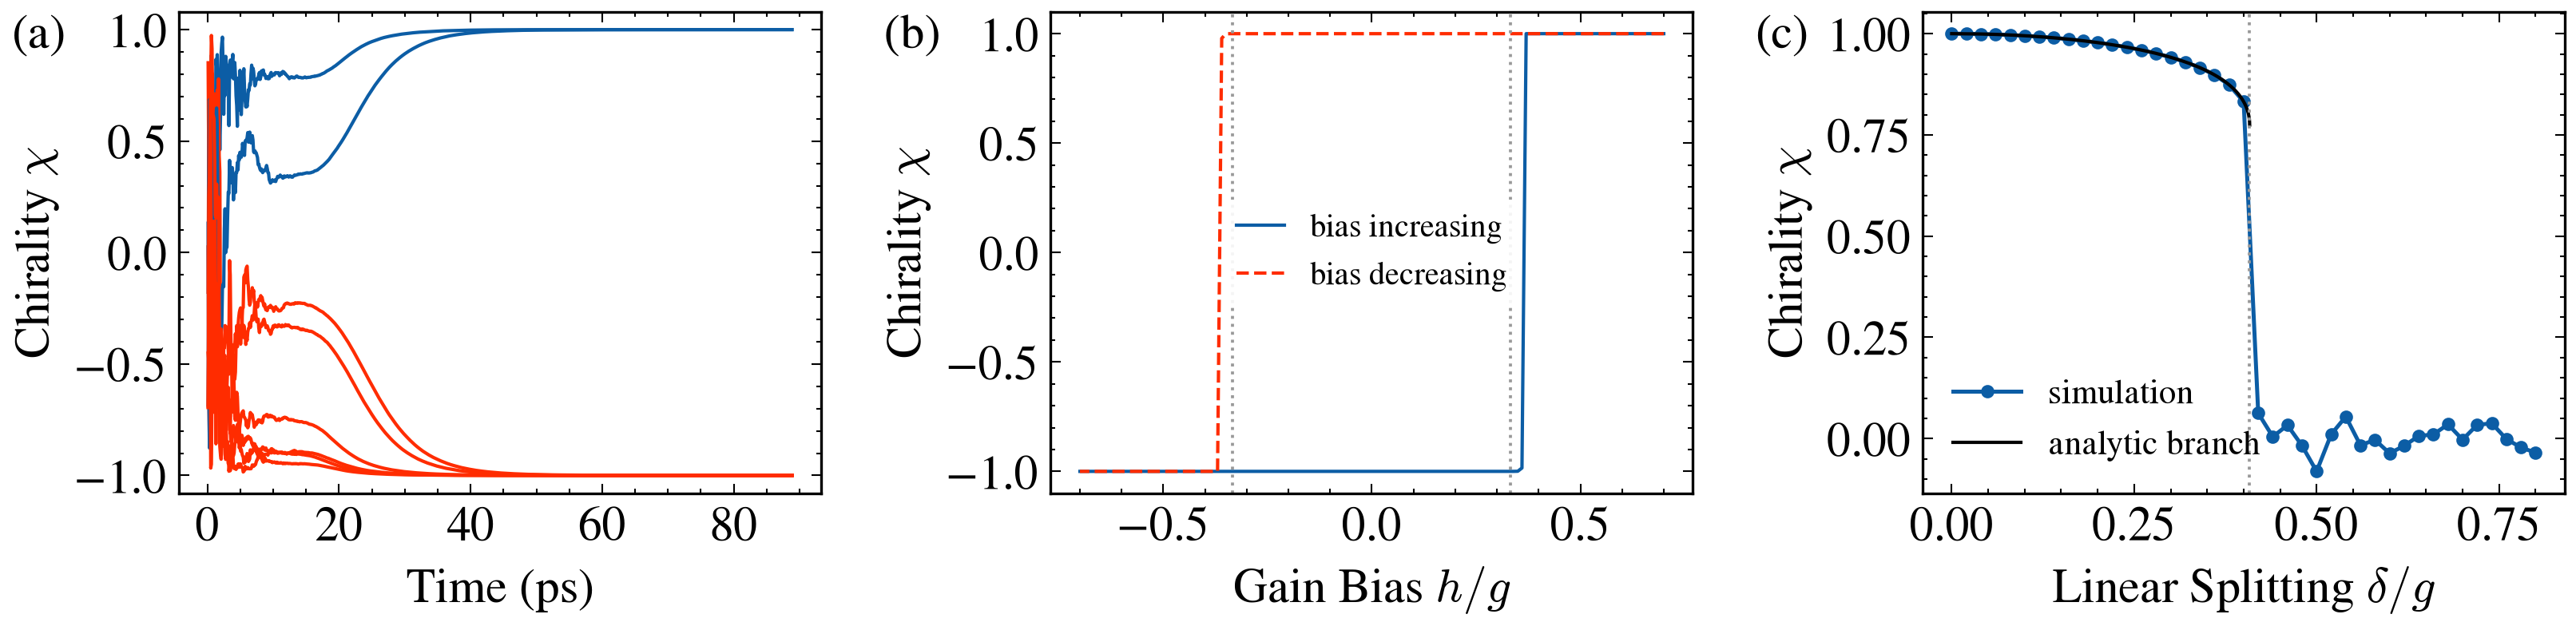

In [12]:
# Load and plot Figure 3
def plot3(path, out):
    d = load_data(path)
    fig, (a, b, c) = three_panels()
    
    fig.set_size_inches(12, 3)
    
    # --- Panel (a): Time Traces ---
    for trace in d["chirality"]:
        a.plot(d["time_ps"], trace, color="C0" if trace[-1] > 0 else "C3", lw=1)
    a.set(ylim=(-1.08, 1.08), xticks=[0, 20, 40, 60, 80])
    a.set_xlabel("Time (ps)", fontsize=font(12))
    
    # --- Panel (b): Hysteresis Loop ---
    mid = len(d["h"]) // 2
    b.plot(d["h"][:mid], d["loop"][:mid], "C0-", label="bias increasing")
    b.plot(d["h"][mid:], d["loop"][mid:], "C3--", label="bias decreasing")
    for h in (-1/3, 1/3):
        b.axvline(h, color=".6", ls=":", lw=0.9)
    b.set_xlabel(r"Gain Bias $h/g$", fontsize=font(12))
    b.legend(loc="center", handlelength=1.5, frameon=True, framealpha=0.9, edgecolor="none", fontsize=font(8))
    
    # --- Panel (c): Bifurcation / Splitting ---
    c.plot(d["split"], d["mean_chirality"], "C0o-", ms=3, lw=1.2, label="simulation")
    c.plot(d["analytic_split"], d["analytic_chi"], "k-", lw=1, label="analytic branch")
    c.axvline(1/np.sqrt(6), color=".6", ls=":", lw=0.9)
    c.set_xlabel(r"Linear Splitting $\delta/g$", fontsize=font(12))
    c.legend(loc="lower left", fontsize=font(8.5))
    
    for ax in [a, b, c]:
        ax.set_ylabel(r"Chirality $\chi$", fontsize=font(12))
        ax.tick_params(axis="both", labelsize=font(12))
        ax.set_box_aspect(3 / 4)
        
    # --- Jalankan finish terlebih dahulu ---
    finish(fig, [a, b, c], out, NAMES[2])
    
    shift_ax(a, dx=0.00, dy=0.00)
    shift_ax(b, dx=-0.03, dy=0.00)
    shift_ax(c, dx=-0.06, dy=0.00)
    
    set_panel_label(fig, a, "(a)", x=-0.26, y=1.0, fontsize=font(12))
    set_panel_label(fig, b, "(b)", x=-0.26, y=1.0, fontsize=font(12))
    set_panel_label(fig, c, "(c)", x=-0.26, y=1.0, fontsize=font(12))
    
    fig.savefig(str(Path(out) / (NAMES[2] + ".png")), dpi=300, bbox_inches="tight")
    fig.savefig(str(Path(out) / (NAMES[2] + ".pdf")), bbox_inches="tight")

plot3(DATA / (NAMES[2] + ".npz"), ROOT / "plots")
display(Image(filename=str(ROOT / "plots" / (NAMES[2] + ".png")), width=950))

## Figure 4. Steady drive and local Floquet gap

Stores the three amplitude and gap curves, exact and leading-order Dirac expressions, the lattice propagation samples, and the full range of amplitudes for the shaded area.

The first cell writes the archive. The following cell controls the figure formatting.

In [13]:
# Calculate and save Figure 4
def calculate4(path):
    mus = np.linspace(.1,.4,61)
    losses = [1.5,1.5,4.]
    refill = [.020,.010,.020]
    amps, gaps, results = [], [], {}
    for loss, Gr in zip(losses,refill):
        amp = np.array([Medium(mu,1000,Gr=Gr,gan_cm=loss,nE=600).steady_circular() for mu in mus])
        gap = np.sqrt(HW0**2+4*amp**2)-HW0
        amps.append(amp)
        gaps.append(gap)
        results[f"gan{loss}_Gr{Gr}"] = {"A_meV_mu250": amp[30]*1000, "gap_meV_mu250": gap[30]*1000,
                                      "A_meV_mu400": amp[-1]*1000, "gap_meV_mu400": gap[-1]*1000}
    xs, xx = np.linspace(.02,.6,30), np.linspace(0,.6,200)
    frequencies = [7.,1.,.07]
    lattice = []
    for w in frequencies:
        row = []
        for x in xs:
            eps,_ = floquet_states(K_PT, x*w/1.5, w, 300 if w>.5 else 900)
            row.append((eps[0,1]-eps[0,0])/w)
        lattice.append(row)
    save_data(path, mu=mus*1000, amp=np.array(amps)*1000, gap=np.array(gaps)*1000,
              loss=losses, refill=np.array(refill)*1000, x=xs, xx=xx, lattice=lattice,
              omega=frequencies, exact=np.sqrt(1+4*xx**2)-1, leading=2*xx**2,
              shade=np.max(amps)/HW0)
    amp = amps[0][30]
    n = (amp/GBAR)**2
    results.update({"lattice_formula_max_abs_err": np.max(np.abs(lattice-(np.sqrt(1+4*xs**2)-1))),
                    "n_coh_per_cell": n, "lambda": amp/(1.5*T_HOP),
                    "u0_pm": amp/(1.5*DTDD)*100,
                    "phonon_power_W_cm2": n*1.5*CM*QE/HBAR*HW0*QE/A_UC_CM2})
    return results

metrics_4 = calculate4(DATA / (NAMES[3] + ".npz"))
record(ROOT, "fig4", metrics_4)
print("Wrote", DATA / (NAMES[3] + ".npz"))

Wrote /home/mainadmin/solihin/symm-break-circ-phonon/data/fig4_floquet_mass.npz


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


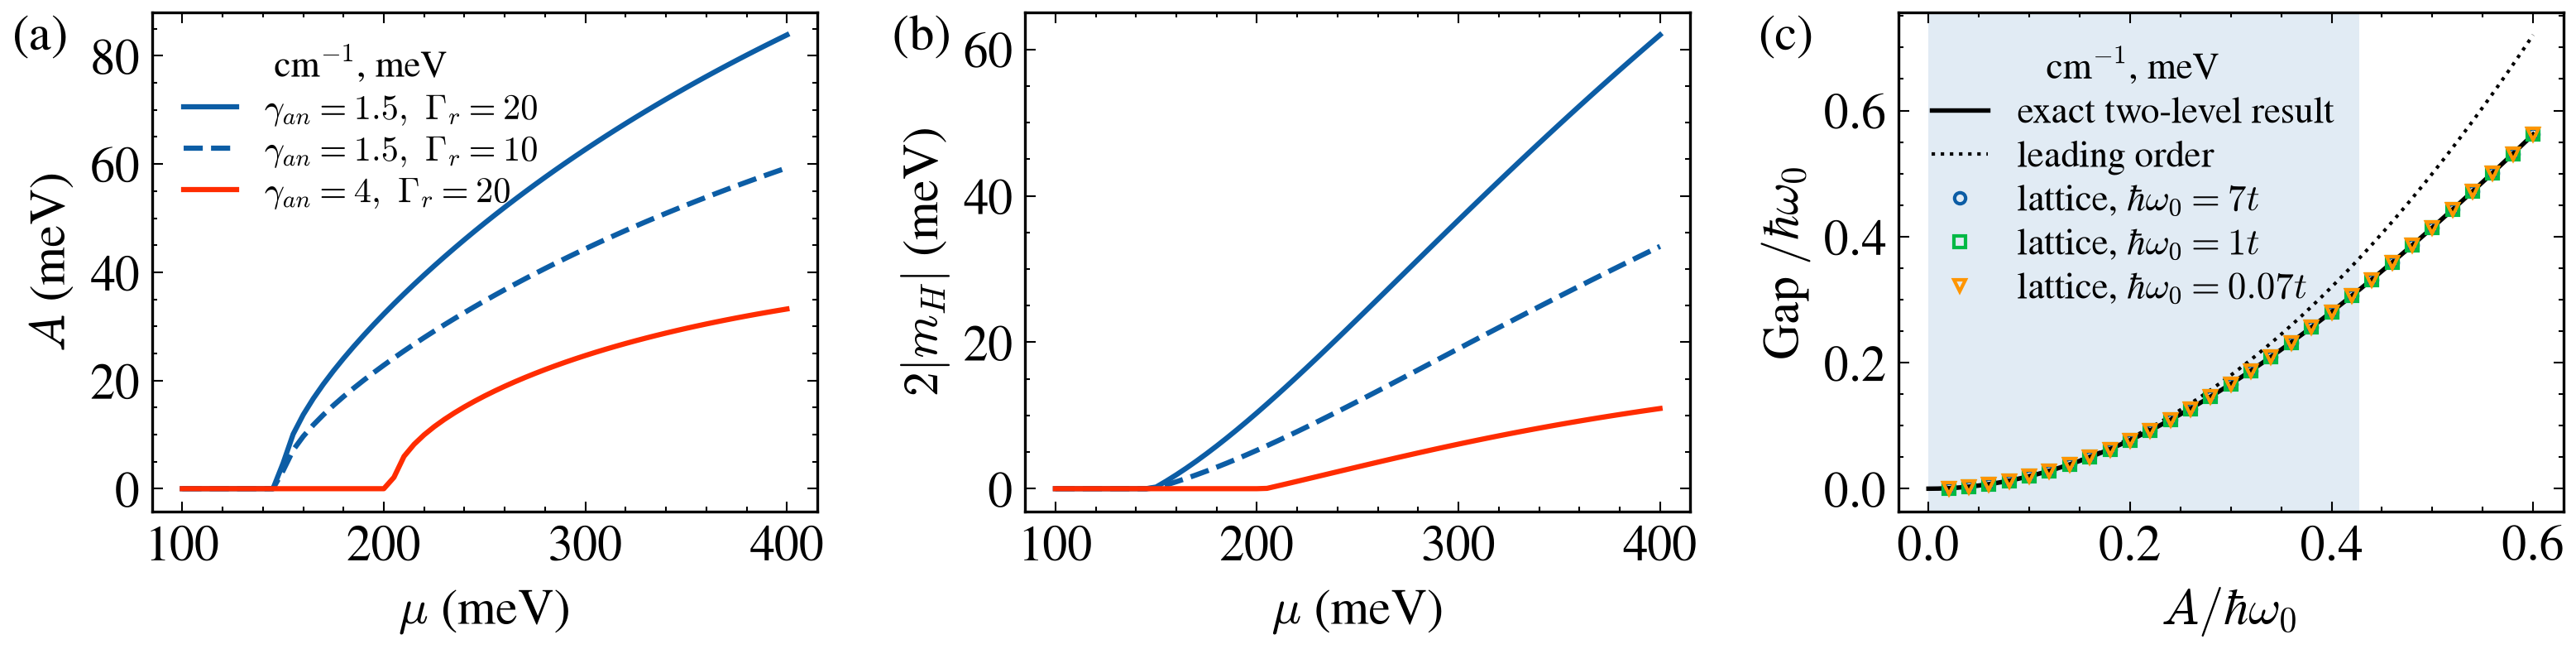

In [14]:
# Load and plot Figure 4
def plot4(path, out):
    d = load_data(path)
    fig, (a, b, c) = three_panels()
    
    fig.set_size_inches(12, 3)
    
    # --- Panel (a) & (b): Drive Amplitude & Dirac-Point Gap ---
    for i, fmt in enumerate(["C0-", "C0--", "C3-"]):
        label = rf"$\gamma_{{an}}={d['loss'][i]:g},\;\Gamma_r={d['refill'][i]:g}$"
        a.plot(d["mu"], d["amp"][i], fmt, lw=1.5, label=label)
        b.plot(d["mu"], d["gap"][i], fmt, lw=1.5)
        
    for ax in (a, b):
        ax.set_xlabel(r"$\mu$ (meV)", fontsize=font(12))
        
    a.set_ylabel(r"$A$ (meV)", fontsize=font(12))
    a.legend(fontsize=font(8.5), title=r"cm$^{-1}$, meV", title_fontsize=font(9),
             loc="upper left", labelspacing=0.18, handlelength=1.5)
    b.set_ylabel(r"$2|m_H|$ (meV)", fontsize=font(12))
    
    # --- Panel (c): Exact vs Leading Order & Lattice ---
    c.plot(d["xx"], d["exact"], "k-", lw=1.3, label="exact two-level result")
    c.plot(d["xx"], d["leading"], "k:", lw=1, label="leading order")
    for w, mk, row in zip(d["omega"], ["o", "s", "v"], d["lattice"]):
        c.plot(d["x"], row, mk, ms=3.2, mfc="none", label=rf"lattice, $\hbar\omega_0={w:g}t$")
    c.axvspan(0, d["shade"], color="C0", alpha=0.12, lw=0)
    c.set_xlabel(r"$A/\hbar\omega_0$", fontsize=font(12))
    c.set_ylabel(r"Gap $/\hbar\omega_0$", fontsize=font(12))
    c.legend(fontsize=font(9), title=r"cm$^{-1}$, meV", title_fontsize=font(9),
             loc="upper left", labelspacing=0.18, handlelength=1.5)

    for ax in [a, b, c]:
        ax.tick_params(axis="both", labelsize=font(12))
        ax.set_box_aspect(3 / 4)
        
    finish(fig, [a, b, c], out, NAMES[3])
    
    shift_ax(a, dx=0.00, dy=0.00)
    shift_ax(b, dx=-0.04, dy=0.00)
    shift_ax(c, dx=-0.08, dy=0.00)
    
    set_panel_label(fig, a, "(a)", x=-0.21, y=1.0, fontsize=font(12))
    set_panel_label(fig, b, "(b)", x=-0.2, y=1.0, fontsize=font(12))
    set_panel_label(fig, c, "(c)", x=-0.21, y=1.0, fontsize=font(12))
    
    fig.savefig(str(Path(out) / (NAMES[3] + ".png")), dpi=300, bbox_inches="tight")
    fig.savefig(str(Path(out) / (NAMES[3] + ".pdf")), bbox_inches="tight")

plot4(DATA / (NAMES[3] + ".npz"), ROOT / "plots")
display(Image(filename=str(ROOT / "plots" / (NAMES[3] + ".png")), width=950))

## Figure 5. Berry curvature and minimum quasienergy gap

Stores the two reciprocal-space curvature maps and every frequency-scan point on both meshes. The scan uses fixed $A/(\hbar\omega_0)=0.3$. At its two largest frequencies, $\lambda>1$ makes it a formal lattice-model benchmark.

The first cell writes the archive. The following cell controls the figure formatting.

In [15]:
# Calculate and save Figure 5
def calculate5(path):
    curvature, results = [], {}
    for r,l,name in ((.4,0,"R"),(0,.4,"L")):
        C,F,g0,gpi = chern_map(r,l,7,60,160)
        curvature.append(F.T*F.size/(2*np.pi))
        results["C_"+name], results["G0_"+name] = C,g0
    rows = []
    for w in np.geomspace(.07,9,12):
        # A/t = (3/2)*lambda. A/(hbar omega) is fixed over the entire scan.
        lam = .3*w/1.5
        meshes = []
        for nk in (60,90):
            C,_,g0,gpi = chern_map(lam,0,w,nk,200 if w>.5 else 600)
            meshes.append((C,min(g0,gpi)/w))
        (c1,d1),(c2,d2) = meshes
        resolved = abs(c1-c2)<1e-6 and d2>1e-3 and abs(d1-d2)<.25*d2
        rows.append([w,d2,float(resolved),c1,c2,lam,d1])
    save_data(path, curvature=curvature, chern=[results["C_R"], results["C_L"]],
              scan=rows, scan_columns=["omega_over_t","gap90_over_omega","resolved",
                                      "C60","C90","lambda","gap60_over_omega"])
    results["scan"] = rows
    return results

metrics_5 = calculate5(DATA / (NAMES[4] + ".npz"))
record(ROOT, "fig5", metrics_5)
print("Wrote", DATA / (NAMES[4] + ".npz"))

Wrote /home/mainadmin/solihin/symm-break-circ-phonon/data/fig5_topology.npz


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


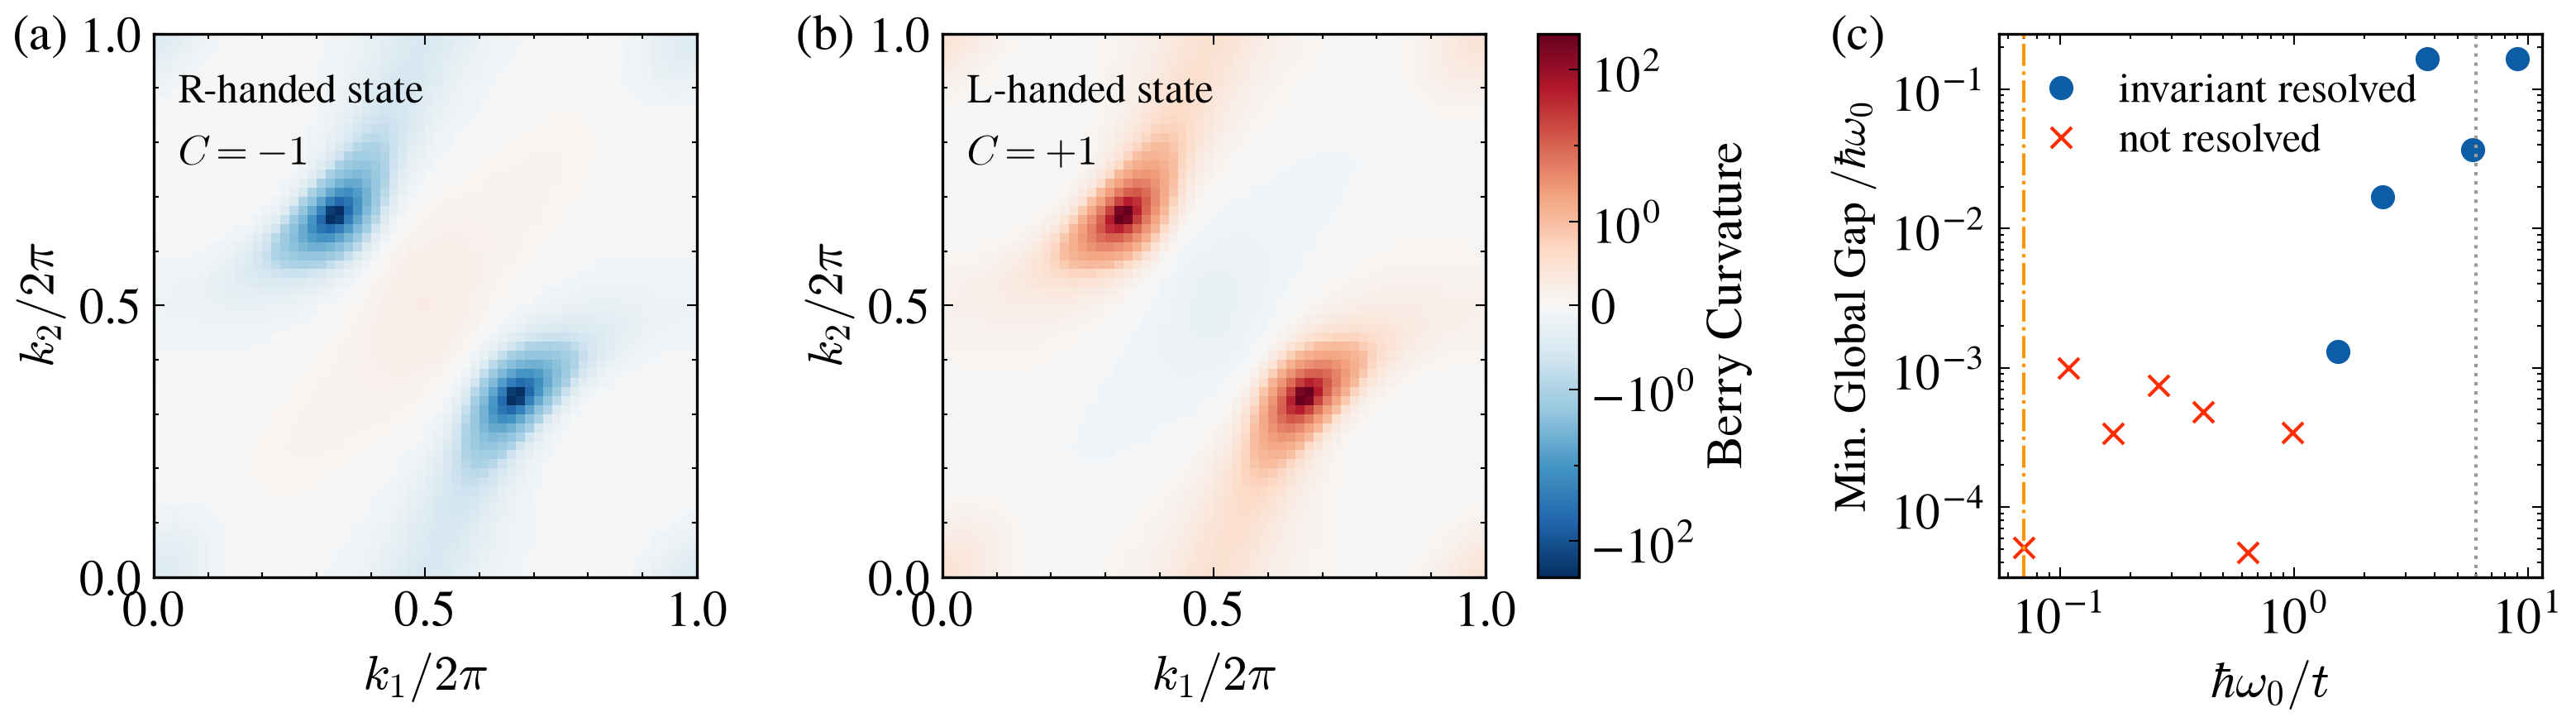

In [16]:
# Load and plot Figure 5
def plot5(path, out):
    from matplotlib.colors import SymLogNorm
    d = load_data(path)
    
    fig = plt.figure(figsize=(12, 3))
    
    a  = fig.add_axes([0.06, 0.18, 0.1825, 0.73])
    b  = fig.add_axes([0.30, 0.18, 0.1825, 0.73])
    cb = fig.add_axes([0.50, 0.18, 0.0140, 0.73])
    c  = fig.add_axes([0.65, 0.18, 0.1825, 0.73])
    
    for i, (ax, hand) in enumerate(zip([a, b], "RL")):
        im = ax.imshow(d["curvature"][i], origin="lower", extent=(0, 1, 0, 1),
                       cmap="RdBu_r", norm=SymLogNorm(1, vmin=-300, vmax=300), interpolation="nearest")
        ax.set(xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
        ax.set_xlabel(r"$k_1/2\pi$", fontsize=font(12))
        ax.set_ylabel(r"$k_2/2\pi$", fontsize=font(12))
        ax.tick_params(axis="both", labelsize=font(12))
        ax.set_aspect("equal")
        ax.text(0.045, 0.95, f"{hand}-handed state\n" + rf"$C={d['chern'][i]:+.0f}$",
                transform=ax.transAxes, va="top", fontsize=font(10))
        
    fig.colorbar(im, cax=cb, orientation="vertical", ticks=[-100, -1, 0, 1, 100])
    cb.tick_params(labelsize=font(12))
    cb.set_ylabel("Berry Curvature", labelpad=2, fontsize=font(12))
    
    scan = d["scan"]
    for flag, mk, col, label in [(1, "o", "C0", "invariant resolved"), (0, "x", "C3", "not resolved")]:
        row = scan[scan[:, 2] == flag]
        c.loglog(row[:, 0], row[:, 1], mk, color=col, label=label)
    c.axvline(6, color=".6", ls=":")
    c.axvline(0.07, color="C2", ls="-.")
    c.set_xlabel(r"$\hbar\omega_0/t$", fontsize=font(12))
    c.set_ylabel(r"Min. Global Gap $/\hbar\omega_0$", fontsize=font(11))
    c.tick_params(axis="both", labelsize=font(12))
    c.set_box_aspect(1)
    c.legend(loc="upper left", fontsize=font(10), handlelength=1.2, labelspacing=0.2)
    
    finish(fig, [a, b, c], out, NAMES[4])
    
    shift_ax(a,  dx=0.00, dy=0.00)
    shift_ax(b,  dx=0.025, dy=0.00)
    shift_ax(cb, dx=0.025, dy=0.00)
    shift_ax(c,  dx=0.03, dy=0.00)
    
    set_panel_label(fig, a, "(a)", x=-0.26, y=1.04, fontsize=font(12))
    set_panel_label(fig, b, "(b)", x=-0.27, y=1.04, fontsize=font(12))
    set_panel_label(fig, c, "(c)", x=-0.31, y=1.04, fontsize=font(12))
    
    fig.savefig(str(Path(out) / (NAMES[4] + ".png")), dpi=300, bbox_inches="tight")
    fig.savefig(str(Path(out) / (NAMES[4] + ".pdf")), bbox_inches="tight")

plot5(DATA / (NAMES[4] + ".npz"), ROOT / "plots")
display(Image(filename=str(ROOT / "plots" / (NAMES[4] + ".png")), width=950))